# TP 2 - Predicción de lluvia en Australia

## 1. Análisis descriptivo

El objetivo es estudiar las observaciones meteorológicas y preparar el problema de clasificación de `RainTomorrow`. 

En este primer avance se revisa el archivo entregado, describimos sus variables y hacemos un diagnostico de lss faltantes.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

In [2]:
# Cargamos el CSV entregado y convierto Date a fecha para resumir el período.
DATA_PATH = Path("weatherAUS_2026C2.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {DATA_PATH.resolve()}")

df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

In [3]:
display(df.head())

,Unnamed: 0,Date,Location,MinTemp,MaxTemp,Rainfall,Evaporation,Sunshine,WindGustDir,WindGustSpeed,...,Humidity3pm,Pressure9am,Pressure3pm,Cloud9am,Cloud3pm,Temp9am,Temp3pm,RainToday,RainTomorrow,RainfallTomorrow
0,0,2008-12-01,Albury,13.6,22.5,0.6,NaN,NaN,W,45.0,...,23.8,1008.1,1007.2,8.0,NaN,16.8,20.8,No,No,0.0
1,1,2008-12-02,Albury,7.3,25.8,0.0,NaN,NaN,WNW,44.0,...,22.1,1011.1,1007.5,NaN,NaN,18.3,24.6,No,No,0.0
2,2,2008-12-03,Albury,13.2,26.2,0.0,NaN,NaN,WSW,46.0,...,31.5,1007.3,1009.4,NaN,2.0,21.2,23.4,No,No,0.0
3,3,2008-12-04,Albury,10.0,28.8,0.0,NaN,NaN,NE,23.0,...,18.5,1017.6,1012.4,NaN,NaN,17.4,26.3,No,No,1.0
4,4,2008-12-05,Albury,17.4,32.4,1.0,NaN,NaN,W,41.0,...,34.6,1010.9,1005.9,7.0,8.0,17.9,29.1,No,No,0.2


### Variables del archivo

El CSV no incluye un diccionario de datos. Esta primera descripción toma los nombres de las columnas y los valores observados en el archivo
| Variable | Qué representa |
| --- | --- |
| `Unnamed: 0` | Índice que quedó guardado junto con el CSV; no describe el clima. |
| `Date` | Fecha asociada a la observación. |
| `Location` | Ciudad o ubicación de la observación. |
| `MinTemp`, `MaxTemp` | Temperatura mínima y máxima. |
| `Rainfall` | Lluvia observada en la fecha de la fila. |
| `Evaporation` | Evaporación observada. |
| `Sunshine` | Horas de sol registradas. |
| `WindGustDir`, `WindGustSpeed` | Dirección y velocidad de la ráfaga máxima. |
| `WindDir9am`, `WindDir3pm` | Dirección del viento cerca de las 9 y las 15 h. |
| `WindSpeed9am`, `WindSpeed3pm` | Velocidad del viento cerca de las 9 y las 15 h. |
| `Humidity9am`, `Humidity3pm` | Humedad observada cerca de las 9 y las 15 h. |
| `Pressure9am`, `Pressure3pm` | Presión observada cerca de las 9 y las 15 h. |
| `Cloud9am`, `Cloud3pm` | Cobertura de nubes cerca de las 9 y las 15 h. |
| `Temp9am`, `Temp3pm` | Temperatura cerca de las 9 y las 15 h. |
| `RainToday` | Indicador categórico de lluvia en la fecha de la fila. |
| `RainTomorrow` | Indicador de lluvia al día siguiente; es la variable objetivo. |
| `RainfallTomorrow` | Cantidad de lluvia del día siguiente, según el nombre de la columna. Se revisa antes de usarla como predictor. |



In [4]:
# Resumo tipos, valores distintos y rangos numéricos para completar la descripción.
estructura = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "valores distintos": df.nunique(dropna=True),
    "faltantes": df.isna().sum(),
})
display(estructura)

variables_numericas = df.select_dtypes(include="number").drop(columns=["Unnamed: 0"])
rangos = variables_numericas.describe().T[["min", "50%", "max"]]
rangos = rangos.rename(columns={"min": "mínimo observado", "50%": "mediana", "max": "máximo observado"})
display(rangos.round(2))

,tipo,valores distintos,faltantes
Unnamed: 0,int64,145412,0
Date,datetime64[us],3435,0
Location,str,49,0
MinTemp,float64,395,1484
MaxTemp,float64,506,1253
Rainfall,float64,681,3260
Evaporation,float64,358,62754
Sunshine,float64,145,69796
WindGustDir,str,16,10316
WindGustSpeed,float64,120,10253


,mínimo observado,mediana,máximo observado
MinTemp,-9.7,12.0,34.1
MaxTemp,-5.1,22.6,49.1
Rainfall,0.0,0.0,371.0
Evaporation,0.0,4.8,145.0
Sunshine,0.0,8.4,14.5
WindGustSpeed,6.0,38.0,135.0
WindSpeed9am,0.0,13.0,130.0
WindSpeed3pm,0.0,18.0,86.0
Humidity9am,0.0,69.9,100.0
Humidity3pm,0.0,52.0,100.0


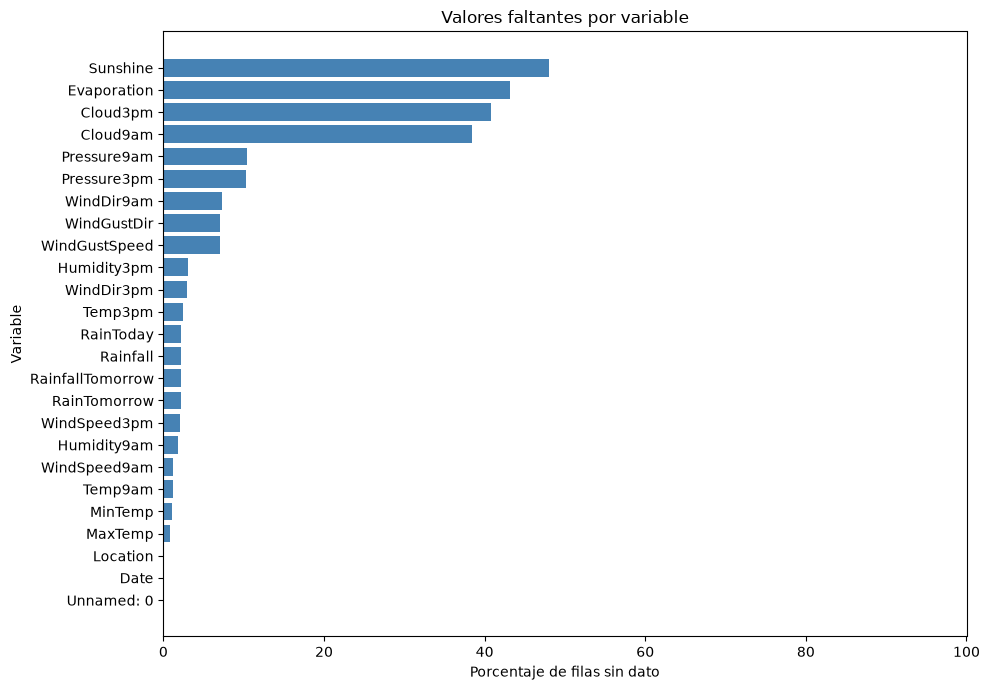

In [5]:
# Calculo y grafico el porcentaje de faltantes para comparar variables en la misma escala.
fig, ax = plt.subplots(figsize=(10, 7))
faltantes = pd.DataFrame({"porcentaje": df.isna().mean() * 100})
faltantes_ordenados = faltantes.sort_values("porcentaje")
ax.barh(faltantes_ordenados.index, faltantes_ordenados["porcentaje"], color="steelblue")
ax.set_title("Valores faltantes por variable")
ax.set_xlabel("Porcentaje de filas sin dato")
ax.set_ylabel("Variable")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### Análisis de Datos y Decisión sobre los faltantes

Conservamos `Sunshine`, `Evaporation`, `Cloud3pm` y `Cloud9am` en el conjunto de datos porque describen condiciones meteorológicas que pueden aportar información sobre la lluvia: horas de sol, evaporación y cobertura de nubes en dos momentos del día. No eliminaremos las filas por tener faltante en alguna de estas cuatro columnas. Si lo hiciéramos, perderíamos 82.854 registros (56,98 % del archivo); entre las filas con `RainTomorrow` conocido, solo conservaríamos 62.349 (43,86 %). Además, los faltantes varían por ubicación y año. El tratamiento de estos predictores se definirá más adelante, después de separar entrenamiento y prueba.

Se excluirán del conjunto de modelado las filas que no tengan valor en `RainTomorrow`. Esta columna es la variable objetivo: sin conocer si llovió al día siguiente, no hay una respuesta observada con la cual entrenar el modelo ni comprobar después si acertó. Tampoco corresponde completar esa etiqueta con una moda o una mediana, porque eso asignaría una respuesta no observada y alteraría la distribución de clases.

Esta decisión se aplica a las filas sin etiqueta. Los faltantes en las variables que describen las condiciones del día se analizarán por separado y, si se conservan, se tratarán durante el preprocesamiento. Una mediana o una moda puede servir como estrategia para ciertos predictores, pero no reemplaza el valor faltante de `RainTomorrow`.

### Visualización de datos

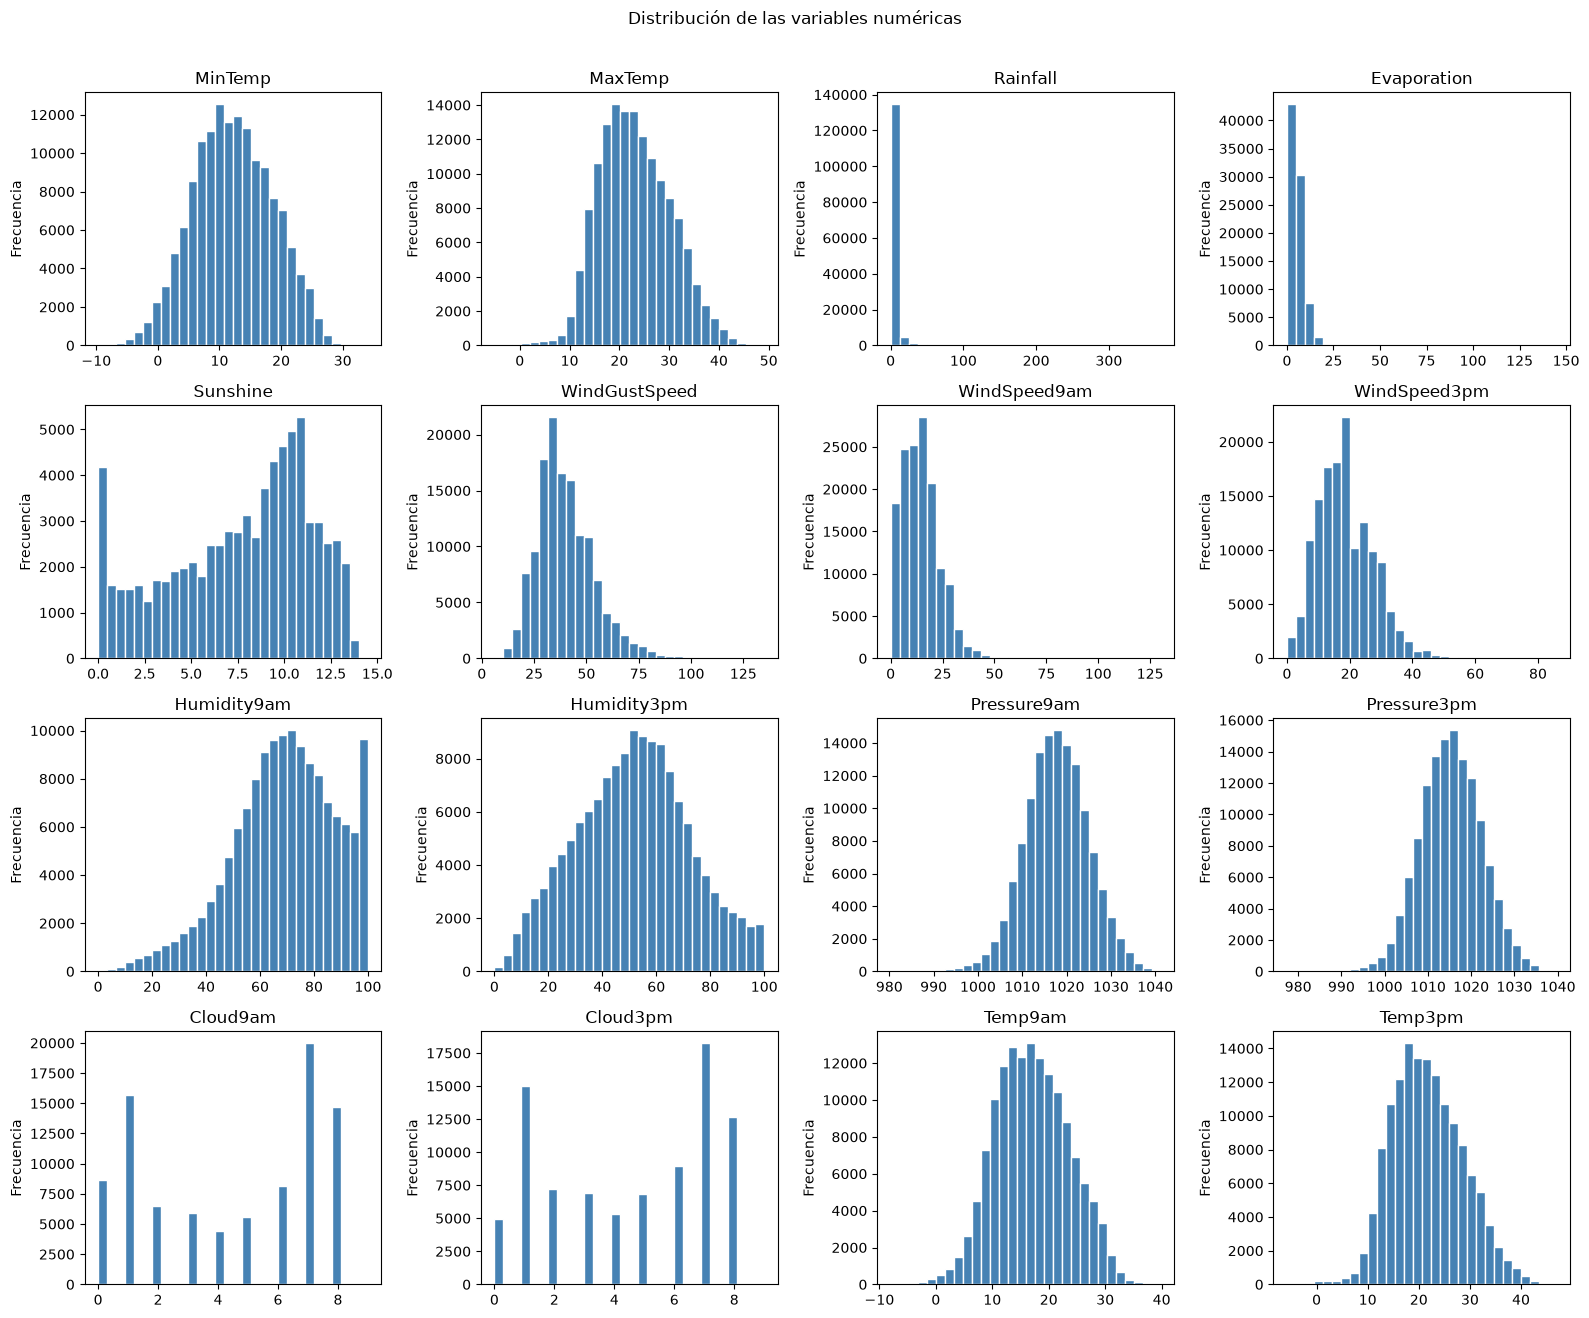

In [6]:
# Grafico las distribuciones de las variables numéricas, excluyendo el índice y la medición del día siguiente.
variables_hist = [
    columna
    for columna in df.select_dtypes(include="number").columns
    if columna not in {"Unnamed: 0", "RainfallTomorrow"}
]

fig, axes = plt.subplots(4, 4, figsize=(16, 13))
for ax, columna in zip(axes.flat, variables_hist):
    datos = df[columna].dropna()
    ax.hist(datos, bins=30, color="steelblue", edgecolor="white")
    ax.set_title(columna)
    ax.set_ylabel("Frecuencia")

for ax in axes.flat[len(variables_hist):]:
    ax.set_visible(False)

fig.suptitle("Distribución de las variables numéricas", y=1.01)
plt.tight_layout()
plt.show()

Para observar asociaciones entre predictores, usamos dos diagramas de dispersión. El color representa la clase observada de RainTomorrow. Se toman hasta 8.000 observaciones completas por gráfico con una semilla fija para mantener la figura legible y reproducible; este muestreo se usa únicamente para graficar.

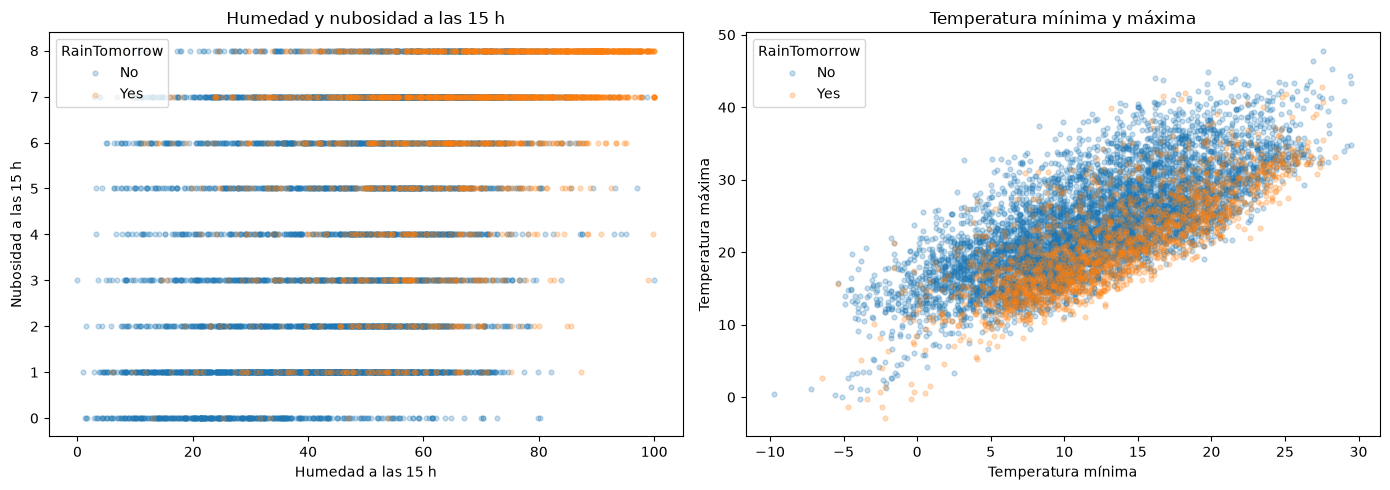

In [7]:
# Comparo humedad con nubosidad y temperatura mínima con máxima, coloreando por la clase objetivo.
colores_clase = {"No": "tab:blue", "Yes": "tab:orange"}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

datos_humedad_nubes = df.dropna(subset=["Humidity3pm", "Cloud3pm", "RainTomorrow"])
if len(datos_humedad_nubes) > 8000:
    datos_humedad_nubes = datos_humedad_nubes.sample(n=8000, random_state=42)

for clase, color in colores_clase.items():
    grupo = datos_humedad_nubes[datos_humedad_nubes["RainTomorrow"] == clase]
    axes[0].scatter(
        grupo["Humidity3pm"], grupo["Cloud3pm"],
        s=12, alpha=0.25, color=color, label=clase
    )
axes[0].set_title("Humedad y nubosidad a las 15 h")
axes[0].set_xlabel("Humedad a las 15 h")
axes[0].set_ylabel("Nubosidad a las 15 h")
axes[0].legend(title="RainTomorrow", loc="upper left")

datos_temperaturas = df.dropna(subset=["MinTemp", "MaxTemp", "RainTomorrow"])
if len(datos_temperaturas) > 8000:
    datos_temperaturas = datos_temperaturas.sample(n=8000, random_state=42)

for clase, color in colores_clase.items():
    grupo = datos_temperaturas[datos_temperaturas["RainTomorrow"] == clase]
    axes[1].scatter(
        grupo["MinTemp"], grupo["MaxTemp"],
        s=12, alpha=0.25, color=color, label=clase
    )
axes[1].set_title("Temperatura mínima y máxima")
axes[1].set_xlabel("Temperatura mínima")
axes[1].set_ylabel("Temperatura máxima")
axes[1].legend(title="RainTomorrow")

plt.tight_layout()
plt.show()

Los diagramas de caja permiten comparar la mediana y el rango intercuartílico de las cuatro variables con mayor proporción de faltantes, separando las observaciones según RainTomorrow. Se ocultan los puntos extremos para que la zona central sea legible; los valores siguen presentes en el conjunto de datos. Los tamaños de muestra se indican en las etiquetas del eje horizontal.

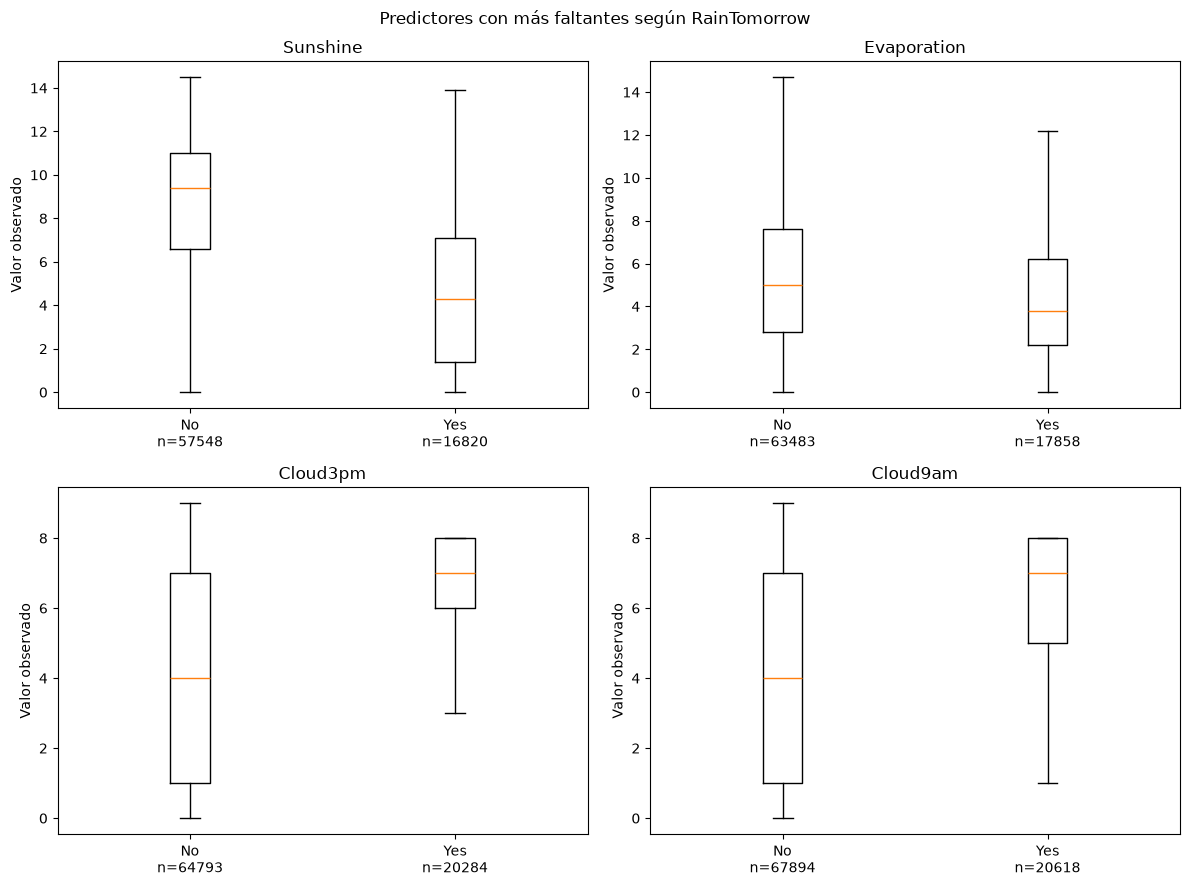

In [8]:
# Comparo por clase las distribuciones de las cuatro variables con mayor proporción de faltantes.
variables_caja = ["Sunshine", "Evaporation", "Cloud3pm", "Cloud9am"]
clases = ["No", "Yes"]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, columna in zip(axes.flat, variables_caja):
    valores_por_clase = [
        df.loc[df["RainTomorrow"] == clase, columna].dropna()
        for clase in clases
    ]
    ax.boxplot(valores_por_clase, showfliers=False)
    ax.set_xticks([1, 2])
    ax.set_xticklabels([
        f"{clase}\nn={len(valores)}"
        for clase, valores in zip(clases, valores_por_clase)
    ])
    ax.set_title(columna)
    ax.set_ylabel("Valor observado")

fig.suptitle("Predictores con más faltantes según RainTomorrow")
plt.tight_layout()
plt.show()

### Lectura de las visualizaciones

Los histogramas muestran que las variables tienen escalas y distribuciones distintas. Por ejemplo, Rainfall concentra muchas observaciones cerca de cero y presenta una cola hacia valores altos; Cloud9am y Cloud3pm toman valores discretos. Esto conviene tenerlo en cuenta al decidir el preprocesamiento.

En los diagramas de caja, la mediana de Sunshine es 9,4 horas para RainTomorrow = No y 4,3 para RainTomorrow = Yes. Para Cloud3pm y Cloud9am, las medianas son 4 y 7, respectivamente; para Evaporation, son 5 y 3,8. En los diagramas de dispersión se observa una relación creciente entre temperatura mínima y máxima, mientras que humedad y nubosidad forman bandas por los valores discretos de nubosidad. Las clases se superponen: estas figuras describen asociaciones del conjunto y no demuestran causalidad ni evalúan el desempeño de un modelo.

Los tamaños de muestra de los diagramas de caja varían porque se omiten los registros sin dato en cada predictor. No se imputaron valores para construir las figuras.

### ¿Está balanceado el dataset?

Para responderlo, observamos la distribución de la variable objetivo RainTomorrow. El cálculo usa únicamente las filas con etiqueta conocida: las observaciones sin RainTomorrow no aportan una clase al conteo y se conservan en df para las decisiones posteriores.

,cantidad,porcentaje
RainTomorrow,,
No,110281,77.58
Yes,31872,22.42


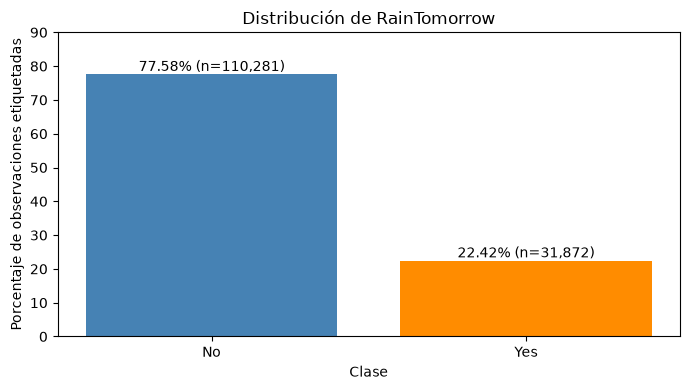

Referencia de mayoría (predecir siempre No): accuracy = 77.58%; recall de Yes = 0.00%.
Filas sin etiqueta excluidas de este conteo: 3,259.


In [9]:
# Cuento las clases conocidas y comparo su proporción con un clasificador constante de referencia.
clases_objetivo = ["No", "Yes"]
conteos_objetivo = (
    df["RainTomorrow"]
    .dropna()
    .value_counts()
    .reindex(clases_objetivo, fill_value=0)
)
total_etiquetado = conteos_objetivo.sum()
balance_objetivo = pd.DataFrame({
    "cantidad": conteos_objetivo,
    "porcentaje": conteos_objetivo / total_etiquetado * 100,
})
balance_objetivo.index.name = "RainTomorrow"
display(balance_objetivo.round({"porcentaje": 2}))

fig, ax = plt.subplots(figsize=(7, 4))
barras = ax.bar(
    balance_objetivo.index,
    balance_objetivo["porcentaje"],
    color=["steelblue", "darkorange"],
)
for barra, porcentaje, cantidad in zip(
    barras, balance_objetivo["porcentaje"], balance_objetivo["cantidad"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 1,
        f"{porcentaje:.2f}% (n={cantidad:,})",
        ha="center",
    )
ax.set_title("Distribución de RainTomorrow")
ax.set_xlabel("Clase")
ax.set_ylabel("Porcentaje de observaciones etiquetadas")
ax.set_ylim(0, 90)
plt.tight_layout()
plt.show()

clase_mayoritaria = conteos_objetivo.idxmax()
accuracy_referencia = conteos_objetivo.max() / total_etiquetado
print(
    f"Referencia de mayoría (predecir siempre {clase_mayoritaria}): "
    f"accuracy = {accuracy_referencia:.2%}; recall de Yes = 0.00%."
)
print(f"Filas sin etiqueta excluidas de este conteo: {df['RainTomorrow'].isna().sum():,}.")

El conjunto no está balanceado respecto de la variable objetivo. Entre las 142.153 filas con etiqueta conocida, 110.281 (77,58 %) corresponden a RainTomorrow = No y 31.872 (22,42 %) a RainTomorrow = Yes; hay aproximadamente 3,46 casos de la clase mayoritaria por cada caso de la minoritaria. Las 3.259 filas sin etiqueta no se incluyen en estas proporciones.

La distribución importa porque un clasificador que siempre predijera No alcanzaría una accuracy de 77,58 %, pero tendría recall de 0 % para los días lluviosos. Por eso, como se trabaja en la unidad de métricas de clasificación, la accuracy por sí sola no alcanza para evaluar el desempeño: luego habrá que revisar métricas por clase y la matriz de confusión.


### Codificación de variables categóricas

Para la predicción usaremos Location, WindGustDir, WindDir9am, WindDir3pm y RainToday como variables categóricas. RainTomorrow es la etiqueta, no un predictor; Date es una fecha y se tratará por separado. No incluimos Unnamed: 0 porque es un índice del archivo ni RainfallTomorrow porque contiene información del día siguiente.

In [10]:
# Resumo las variables categóricas candidatas y algunos de sus valores observados.
columnas_categoricas = [
    "Location",
    "WindGustDir",
    "WindDir9am",
    "WindDir3pm",
    "RainToday",
]
resumen_categoricas = pd.DataFrame({
    "valores distintos": df[columnas_categoricas].nunique(dropna=True),
    "faltantes": df[columnas_categoricas].isna().sum(),
    "ejemplos": {
        columna: ", ".join(
            df[columna].dropna().astype(str).unique()[:5]
        )
        for columna in columnas_categoricas
    },
})
display(resumen_categoricas)

,valores distintos,faltantes,ejemplos
Location,49,0,"Albury, BadgerysCreek, Cobar, CoffsHarbour, Moree"
WindGustDir,16,10316,"W, WNW, WSW, NE, NNW"
WindDir9am,16,10562,"W, NNW, SE, ENE, SW"
WindDir3pm,16,4226,"WNW, WSW, E, NW, W"
RainToday,2,3260,"No, Yes"


Estas variables son nominales: sus categorías no tienen un orden numérico natural. Por eso elegimos OneHotEncoder y no asignamos números enteros arbitrarios a direcciones de viento o ubicaciones. drop="first" deja una categoría de referencia por variable, como en el ejemplo de get_dummies con drop_first de la cátedra; handle_unknown="ignore" evita errores si aparece una categoría nueva. Los valores faltantes de estas columnas se conservarán como una categoría propia.

Primero completaremos la matriz de correlación como parte del análisis descriptivo. Después fijaremos la partición train/test y ajustaremos el codificador solo con entrenamiento. La partición debe quedar antes del escalado, para que el escalador tampoco aprenda de los datos de prueba.